In [ ]:
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset, random_split
import pandas as pd

from src.dataset import LOLv2Dataset
from train import train, evaluate_model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42

In [2]:
# test data pipeline batch
ROOT = "./dataset/LOL-v2/Real_captured"

train_full_dataset = LOLv2Dataset(
    root=ROOT,
    split="Train",
    patch_size=256,
    augment=True
)

test_dataset = LOLv2Dataset(
    root=ROOT,
    split="Test",
    augment=False
)

train_size = int(0.9 * len(train_full_dataset))
val_size = (len(train_full_dataset) - train_size)

split_generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset = random_split(
    train_full_dataset,
    [train_size, val_size],
    generator=split_generator
)

# Load the data into torch (this is kinda painful to change cuz i dont have config maybe later lol)
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    generator=split_generator,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)

# Batch size 1 avoids issues if test image sizes differ
test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

# Inspect one batch
low, normal = next(iter(train_loader))

print("Low shape:", low.shape)
print("Normal shape:", normal.shape)

print("Low range:", low.min().item(), low.max().item())
print("Normal range:", normal.min().item(), normal.max().item())

Train: 689 image pairs loaded
Test: 100 image pairs loaded
Low shape: torch.Size([8, 3, 256, 256])
Normal shape: torch.Size([8, 3, 256, 256])
Low range: 0.0 0.34117648005485535
Normal range: 0.0 1.0


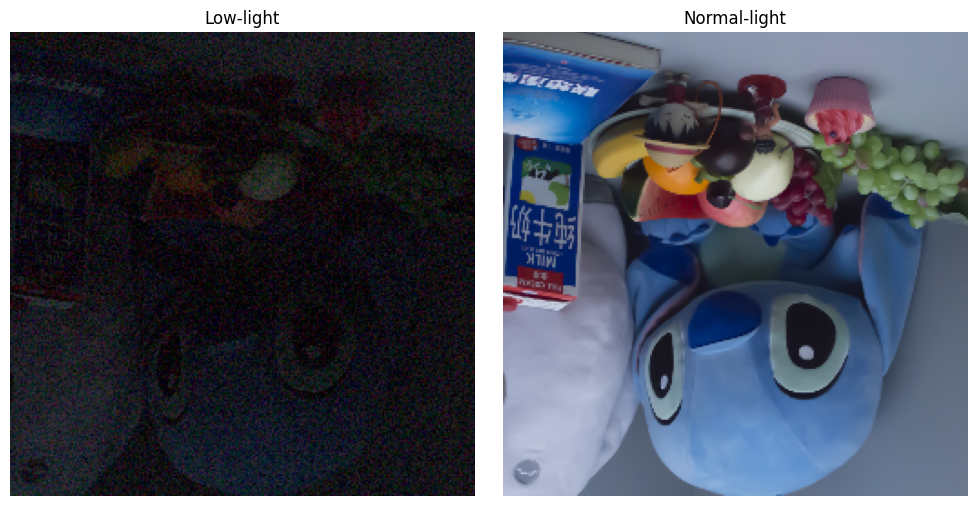

In [3]:
# visualize 1 set of images
low, normal = train_dataset[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(low.permute(1, 2, 0))
axes[0].set_title("Low-light")

axes[1].imshow(normal.permute(1, 2, 0))
axes[1].set_title("Normal-light")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# test Direct CNN model

model, history, best = train(SEED, train_loader, val_loader, 100, 1e-3, len(train_dataset), len(val_dataset))


START TRAINING - SEED 42
Seed 42 | Epoch 001/100 | Train: 0.163985 | Val: 0.134982 | Best Val: 0.134982
Seed 42 | Epoch 002/100 | Train: 0.140925 | Val: 0.128228 | Best Val: 0.128228
Seed 42 | Epoch 003/100 | Train: 0.135272 | Val: 0.127353 | Best Val: 0.127353
Seed 42 | Epoch 004/100 | Train: 0.135044 | Val: 0.123823 | Best Val: 0.123823
Seed 42 | Epoch 005/100 | Train: 0.127960 | Val: 0.125833 | Best Val: 0.123823
Seed 42 | Epoch 006/100 | Train: 0.128016 | Val: 0.129497 | Best Val: 0.123823
Seed 42 | Epoch 007/100 | Train: 0.129980 | Val: 0.124384 | Best Val: 0.123823
Seed 42 | Epoch 008/100 | Train: 0.128172 | Val: 0.116168 | Best Val: 0.116168
Seed 42 | Epoch 009/100 | Train: 0.126085 | Val: 0.125983 | Best Val: 0.116168
Seed 42 | Epoch 010/100 | Train: 0.127968 | Val: 0.115875 | Best Val: 0.115875
Seed 42 | Epoch 011/100 | Train: 0.126195 | Val: 0.116641 | Best Val: 0.115875
Seed 42 | Epoch 012/100 | Train: 0.126290 | Val: 0.121203 | Best Val: 0.115875
Seed 42 | Epoch 013/100 | 

Output shape: torch.Size([3, 256, 256])


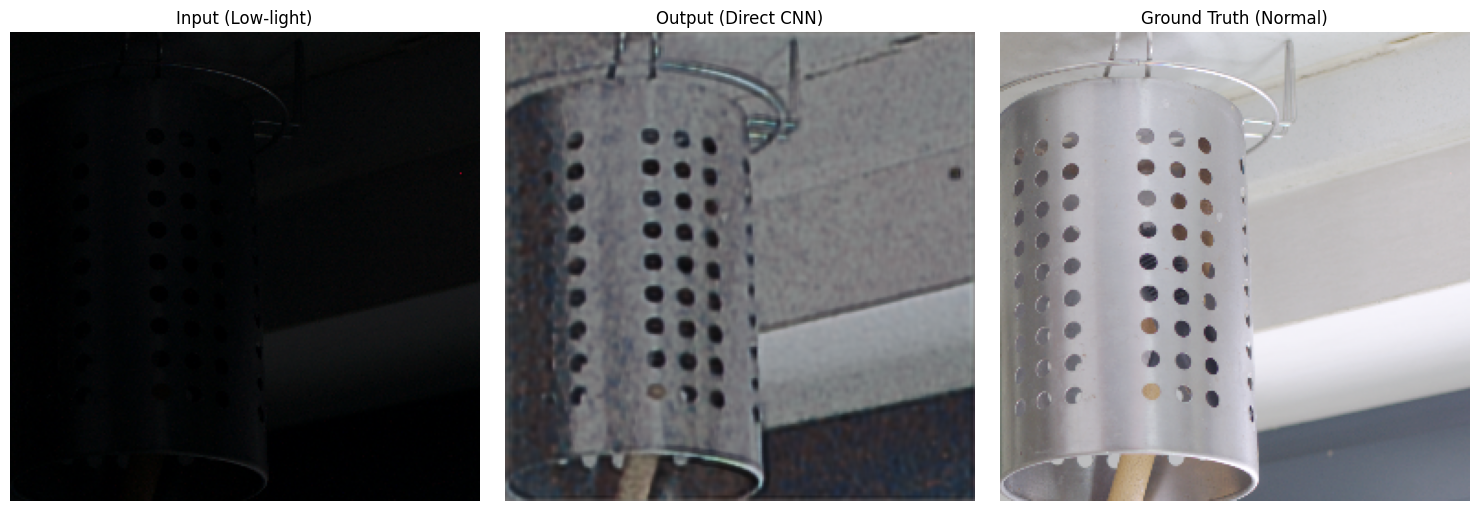

In [5]:
# visualize the output
model.eval()

low, normal = train_dataset[3]
low_input = low.unsqueeze(0).to(device) # return batch dimension: (3, H, W) -> (1, 3, H, W)
# Inference
with torch.no_grad():
    output = model(low_input)

# Remove batch dimension and move to CPU
output = output.squeeze(0).cpu()

print("Output shape:", output.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    low,
    output,
    normal
]

titles = [
    "Input (Low-light)",
    "Output (Direct CNN)",
    "Ground Truth (Normal)"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# evaluate the model
df = evaluate_model(model, SEED, test_dataset)

print(df.groupby("Method")[["MLI", "CI", "E", "AG"]].mean())



Evaluating seed 42...
                   MLI        CI         E        AG
Method                                              
Ground Truth  0.370629  0.145143  6.886666  0.026573
Input         0.056857  0.042298  4.711329  0.009555
Output        0.465074  0.131654  6.864228  0.026746
